# 01 · Base de conhecimento

Fase 2 do plano: documentos oficiais baixados, texto extraído e dividido em trechos com fonte e
metadados. Este notebook só **lê** os artefatos gerados por `scripts/construir_base.py`:

- `base/fontes.csv`: tabela da base (fonte, formato, licença, nº de trechos, hash, data de acesso);
- `base/chunks.jsonl`: trechos dos atos oficiais (versionados no git);
- `base/local/chunks_govbr.jsonl`: trechos das páginas gov.br, gerados localmente e fora do git por
  causa da licença CC BY-ND 3.0 (aqui aparecem só as contagens, nunca o texto);
- `base/descartes.csv`: o que foi descartado e por quê.

Para regenerar: `python scripts/construir_base.py --etapa base`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from src.ingestao import base

pd.set_option("display.max_colwidth", 70)
fontes = pd.read_csv(base.FONTES)
chunks = pd.DataFrame(base.carregar_chunks(incluir_locais=True))
descartes = pd.read_csv(base.DESCARTES)
print(f"{len(fontes)} documentos | {len(chunks)} trechos "
      f"({chunks['versionado'].sum()} versionados, {(~chunks['versionado']).sum()} locais)")

19 documentos | 1812 trechos (1698 versionados, 114 locais)


## Tabela da base

In [2]:
fontes[["id", "documento", "orgao", "formato", "licenca", "recorte", "n_trechos",
        "n_tokens", "texto_versionado"]]

,id,documento,orgao,formato,licenca,recorte,n_trechos,n_tokens,texto_versionado
0,D01,"Resolução Normativa ANEEL nº 1.000, de 7 de dezembro de 2021 (text...",ANEEL,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV)","integral, sem os Anexos II e III",1125,212610,sim
1,D02,"Lei nº 12.212, de 20 de janeiro de 2010 (versão compilada)",Presidência da República,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV); Portaria SG/PR nº 130/2021",integral,17,2475,sim
2,D03,"Lei nº 15.235, de 8 de outubro de 2025 (conversão da MP nº 1.300/2...",Presidência da República,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV); Portaria SG/PR nº 130/2021",integral,12,2202,sim
3,D04,"Portaria Interministerial MME/MS nº 630, de 8 de novembro de 2011",MME e Ministério da Saúde,PDF,"ato oficial (Lei 9.610/1998, art. 8º, IV); PDF disponibilizado no ...",integral,6,816,sim
4,D05,"Resolução Normativa ANEEL nº 1.147, de 9 de dezembro de 2025",ANEEL,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV)",só dispositivos próprios (sem artigos que alteram outras normas),9,1263,sim
5,D06,"Resolução Normativa ANEEL nº 1.137, de 21 de outubro de 2025",ANEEL,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV)",só dispositivos próprios (sem artigos que alteram outras normas),17,1964,sim
6,D07,"PRODIST, Módulo 8: Qualidade do Fornecimento de Energia Elétrica (...",ANEEL,PDF,"ato oficial (Lei 9.610/1998, art. 8º, IV)","seções 8.2, 8.3, anexo-8.B",190,26338,sim
7,D08,"PRODIST, Módulo 9: Ressarcimento de Danos Elétricos (versão vigente)",ANEEL,PDF,"ato oficial (Lei 9.610/1998, art. 8º, IV)",integral,74,7645,sim
8,D09,"Lei nº 14.300, de 6 de janeiro de 2022 (marco legal da micro e min...",Presidência da República,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV); Portaria SG/PR nº 130/2021",integral,67,10997,sim
9,D10,"Lei nº 8.078, de 11 de setembro de 1990 - Código de Defesa do Cons...",Presidência da República,HTML,"ato oficial (Lei 9.610/1998, art. 8º, IV); Portaria SG/PR nº 130/2021",só o Título I,84,15585,sim


## Trechos e tokens por documento

In [3]:
por_doc = chunks.groupby("doc_id")["n_tokens"].agg(
    trechos="count", tokens_total="sum", media="mean", minimo="min", maximo="max").round(0)
por_doc

,trechos,tokens_total,media,minimo,maximo
doc_id,,,,,
D01,1125,212610,189.0,54,399
D02,17,2475,146.0,23,335
D03,12,2202,184.0,58,320
D04,6,816,136.0,52,260
D05,9,1263,140.0,61,236
D06,17,1964,116.0,39,287
D07,190,26338,139.0,48,381
D08,74,7645,103.0,38,325
D09,67,10997,164.0,35,258


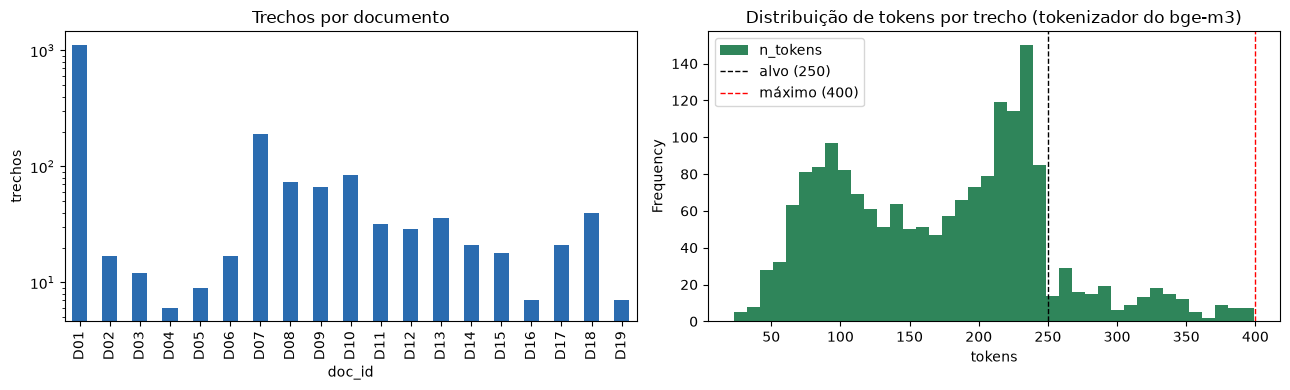

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
por_doc["trechos"].plot.bar(ax=eixos[0], color="#2b6cb0")
eixos[0].set_title("Trechos por documento")
eixos[0].set_ylabel("trechos")
eixos[0].set_yscale("log")
chunks["n_tokens"].plot.hist(ax=eixos[1], bins=40, color="#2f855a")
eixos[1].axvline(250, color="k", ls="--", lw=1, label="alvo (250)")
eixos[1].axvline(400, color="r", ls="--", lw=1, label="máximo (400)")
eixos[1].set_title("Distribuição de tokens por trecho (tokenizador do bge-m3)")
eixos[1].set_xlabel("tokens")
eixos[1].legend()
plt.tight_layout()
plt.show()

In [5]:
chunks["n_tokens"].describe(percentiles=[0.1, 0.5, 0.9]).round(1)

count    1812.0
mean      173.0
std        76.3
min        23.0
10%        75.0
50%       177.0
90%       257.9
max       399.0
Name: n_tokens, dtype: float64

## Descartes

Texto revogado (tachado) é removido antes da extração e não aparece aqui; os descartes abaixo são
o que sobrou de não citável: preâmbulos, assinaturas, sumário, dispositivos revogados ou vetados e o
que ficou fora dos recortes aprovados (CDC só Título I; seções do PRODIST/PRORET; nos atos que
alteram outros, só os dispositivos próprios).

In [6]:
descartes.groupby(["doc_id", "motivo"]).size().unstack(fill_value=0)

motivo,anexo excluído do recorte,assinatura/nota de publicação,cabeçalho/rodapé repetido,dispositivo revogado/vetado,fora do recorte (dispositivos_proprios),fora do recorte (secoes),fora do recorte (titulo),preâmbulo/cabeçalho,índice/sumário
doc_id,,,,,,,,,
D01,2,3,0,0,0,0,0,6,223
D02,0,4,0,4,0,0,0,2,0
D03,0,5,0,0,0,0,0,2,0
D04,0,0,0,0,0,0,0,1,0
D05,0,2,0,0,9,0,0,4,0
D06,0,2,0,0,10,0,0,11,0
D07,0,0,0,0,0,165,0,0,0
D09,0,2,0,1,0,0,0,2,0
D10,0,4,0,42,0,0,55,2,0


## Marcas de qualidade nos trechos

In [7]:
resumo = pd.DataFrame({
    "com tabela ou fórmula": chunks.groupby("doc_id")["contem_tabela"].sum(),
    "com notas de redação": chunks.groupby("doc_id")["notas_redacao"].apply(
        lambda s: sum(bool(x) for x in s)),
    "com alerta de desatualização": chunks.groupby("doc_id")["alerta"].apply(
        lambda s: s.notna().sum()),
})
resumo[resumo.sum(axis=1) > 0]

,com tabela ou fórmula,com notas de redação,com alerta de desatualização
doc_id,,,
D01,30,401,0
D02,0,5,0
D03,0,7,0
D07,36,0,0
D09,0,7,0
D10,0,36,0
D11,0,9,0
D14,0,0,21
D15,0,0,18


## Exemplos de trechos (só atos oficiais)

In [8]:
for cid in ["D01-art362", "D02-art1", "D07-s8.2-item220a"]:
    linha = chunks.loc[chunks["chunk_id"] == cid]
    if linha.empty:
        continue
    c = linha.iloc[0]
    print(f"--- {c.chunk_id} | {c.n_tokens} tokens | notas: {c.notas_redacao[:2]}")
    print(c.texto[:700], "\n")

--- D01-art362 | 375 tokens | notas: []
REN 1.000/2021 > TÍTULO I – PARTE GERAL > CAPÍTULO XIII – DA SUSPENSÃO DO FORNECIMENTO > Seção VII – Da Religação das Instalações > Art. 362
Art. 362. A distribuidora deve restabelecer o fornecimento de energia elétrica nos seguintes prazos, contados de forma contínua e sem interrupção:
I - 4 horas: para religação em caso de suspensão indevida do fornecimento;
II - 4 horas: para religação de urgência de instalações localizadas em área urbana;
III - 8 horas: para religação de urgência de instalações localizadas em área rural;
IV - 24 horas: para religação normal de instalações localizadas em área urbana; e
V - 48 horas: para religação normal de instalações localizadas em área rural.
§ 1º Em c 

--- D02-art1 | 171 tokens | notas: ['(Redação dada pela Lei nº 15.235, de 2025)', '(Revogado pela Lei nº 15.235, de 2025)']
Lei 12.212/2010 > Art. 1º
Art. 1º A Tarifa Social de Energia Elétrica, de que trata a Lei nº 10.438, de 26 de abril de 2002, para os 

## Verificações

In [9]:
versionados = chunks[chunks["versionado"]]
locais_ids = set(fontes.loc[fontes["texto_versionado"] != "sim", "id"])
checagens = {
    "chunk_id únicos": chunks["chunk_id"].is_unique,
    "nenhum trecho vazio": bool(chunks["texto"].str.strip().astype(bool).all()),
    "todos com até 400 tokens": bool((chunks["n_tokens"] <= 400).all()),
    "nenhuma página gov.br no arquivo versionado": not versionados["doc_id"].isin(locais_ids).any(),
    "total entre 300 e 3.000 trechos": 300 <= len(chunks) <= 3000,
    "documentos entre 12 e 20": 12 <= len(fontes) <= 20,
}
pd.Series(checagens, name="ok")

chunk_id únicos                                True
nenhum trecho vazio                            True
todos com até 400 tokens                       True
nenhuma página gov.br no arquivo versionado    True
total entre 300 e 3.000 trechos                True
documentos entre 12 e 20                       True
Name: ok, dtype: bool

## Limitações conhecidas

- **PDF do PRODIST:** as letras das alíneas (a, b, c...) são listas automáticas no PDF e não saem
  na extração; o texto que cita "alínea b" continua íntegro, mas a lista fica sem as letras.
  Equações e tabelas saem achatadas: esses trechos estão marcados com `contem_tabela`.
- **Páginas explicativas:** D14, D15 e D16 foram modificadas antes de normas recentes (ver o campo
  `alerta`); em conflito, vale o texto normativo.
- **Retrato com data:** a base reflete as fontes em 07/11/2026 (`data_consulta` e `sha256_doc` em
  cada trecho). As páginas gov.br são baixadas de novo ao reproduzir e podem ter mudado.